## Fase 3. Establecer un problema a resolver con ML.

Problema: Predecir la demanda por tienda y categoría para una determinada semana.

target: units_sold
features: todas las demás columnas (se elegirán más adelante)

Pasos:
1. Definir features y crear el dataset preprocesado.
2. Crear un modelo lineal (modelo base por simplicidad)
3. Preparar datos procesados; guardarlos en la carpeta processed; separar en datos de prueba y entrenamiento.
4. Entrenar 2 modelos: lineal y LightGBM.
5. Evaluar los modelos con los datos de prueba
6. Guardar resultados
7. Conclusiones

## Imports


In [ ]:
import os
import sys
sys.path.append("..") # Add parent directory to sys.path for module imports

import pandas as pd
import numpy as np
import pickle
import joblib

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from functions.graficar_pred_vs_real import graficar_pred_vs_real

## Cargar datos

In [2]:
root = ".."
folder_raw_datasets = "datasets/raw"
data_version = "20261028"
file_calendar = "calendar.csv"
file_stores = "stores.csv"
file_transactions = "transactions.csv"

route_calendar = os.path.join(root,folder_raw_datasets,data_version,file_calendar)
route_stores = os.path.join(root,folder_raw_datasets,data_version,file_stores)
route_transactions = os.path.join(root,folder_raw_datasets,data_version,file_transactions)


calendar = pd.read_csv(route_calendar)
stores = pd.read_csv(route_stores)
transactions = pd.read_csv(route_transactions)

## Procesamiento de datos


In [3]:
# Convertir las columnas de fecha a tipo datetime para facilitar el merge y análisis posterior
calendar["date"] = pd.to_datetime(calendar["date"],format="%Y-%m-%d") 
transactions["date"] = pd.to_datetime(transactions["date"],format="%Y-%m-%d")

# Unir las tablas de transacciones con tiendas y calendario para tener un dataset completo
data = transactions.merge(stores, on="store_id", how="left")
data = data.merge(calendar, on="date", how="left")

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 203958 entries, 0 to 203957
Data columns (total 35 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   date                  203958 non-null  datetime64[us]
 1   store_id              203958 non-null  str           
 2   category              203958 non-null  str           
 3   total_transactions    203958 non-null  int64         
 4   cash_transactions     191835 non-null  float64       
 5   card_transactions     203958 non-null  int64         
 6   amount_total          203958 non-null  float64       
 7   amount_cash           191835 non-null  float64       
 8   amount_card           203958 non-null  float64       
 9   units_sold            197840 non-null  float64       
 10  avg_ticket            199084 non-null  float64       
 11  has_promotion         203958 non-null  int64         
 12  replenishment_signal  202998 non-null  float64       
 13  store_form

### Agregar columnas de lag y medias móviles

In [5]:
# Ordenar los datos cronológicamente dentro de cada tienda y categoría
data = data.sort_values(
    by=["store_id", "category", "date"]
).copy()

groups = data.groupby(["store_id", "category"])

# Variables históricas de transacciones
data["transactions_lag_1"] = groups["total_transactions"].shift(1)
data["transactions_lag_7"] = groups["total_transactions"].shift(7)
data["transactions_lag_14"] = groups["total_transactions"].shift(14)

for window in [7, 14, 21]:
    data[f"transactions_rolling_mean_{window}"] = (
        groups["total_transactions"]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# Variables históricas de importes
for lag in [1, 7, 14]:
    data[f"amount_lag_{lag}"] = groups["amount_total"].shift(lag)

for window in [7, 14, 21]:
    data[f"amount_rolling_mean_{window}"] = (
        groups["amount_total"]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 203958 entries, 0 to 203957
Data columns (total 47 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   date                          203958 non-null  datetime64[us]
 1   store_id                      203958 non-null  str           
 2   category                      203958 non-null  str           
 3   total_transactions            203958 non-null  int64         
 4   cash_transactions             191835 non-null  float64       
 5   card_transactions             203958 non-null  int64         
 6   amount_total                  203958 non-null  float64       
 7   amount_cash                   191835 non-null  float64       
 8   amount_card                   203958 non-null  float64       
 9   units_sold                    197840 non-null  float64       
 10  avg_ticket                    199084 non-null  float64       
 11  has_promotion           

In [7]:
# Eliminar filas donde la columna units_sold sea nula
data = data.dropna(subset=["units_sold"])

### Eliminar columnas innecesarias

Por simplicidad y por tiempo limitado eliminaré las siguienes columnas:

- amount_cash, amount_card, amount_total: Son cantidades del periodo objetivo; no las conoceré para hacer las predicciones y son redundantes entre ellas
- cash_transactions, card_transactions, total_transactions: Son transacciones del periodo objetivo; no las conoceré para hacer las predicciones y son redundantes entre ellas
- avg_ticket: Es una métrica derivada de las ventas y transacciones; podría introducir fuga de información.
- holiday_name: El nombre del festivo no aporta información útil al modelo.
- day_name: Es redundante con day_of_week.
- quarter: Se deriva de month; con el mes debería ser suficiente.
- season: Se deriva del month; con el mes debería ser suficiente.
- replenishment_signal: Ya tengo los lags y las medias móviles, creo que esta columna no aporta información útil.


In [8]:
data = data.drop(columns=[
    "amount_cash", "amount_card", "amount_total",
    "cash_transactions", "card_transactions", "total_transactions",
    "avg_ticket", "holiday_name", "day_name", "quarter", "season",
    "replenishment_signal"])



In [9]:
data.info()

<class 'pandas.DataFrame'>
Index: 197840 entries, 0 to 203957
Data columns (total 35 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   date                          197840 non-null  datetime64[us]
 1   store_id                      197840 non-null  str           
 2   category                      197840 non-null  str           
 3   units_sold                    197840 non-null  float64       
 4   has_promotion                 197840 non-null  int64         
 5   store_format                  197840 non-null  str           
 6   region                        197840 non-null  str           
 7   size_sqm                      197840 non-null  int64         
 8   num_checkouts                 197840 non-null  int64         
 9   opening_year                  197840 non-null  int64         
 10  socioeconomic_level           197840 non-null  str           
 11  has_pharmacy                 

## Crear variables de Predicción y Objetivo

In [10]:
# Crear las variables objetivo y las variables de predicción (datos aleatorios)
X = data.drop(columns=["units_sold", "date"])
y = data["units_sold"]
# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# Crear las variables objetivo y las variables de predicción respetando el orden temporal

# Ordenar cronológicamente
data = data.sort_values("date").copy()

# Definir el punto de corte temporal
cutoff = data["date"].quantile(0.8)

# Separar entrenamiento y prueba
train_data = data[data["date"] < cutoff].copy()
test_data = data[data["date"] >= cutoff].copy()

# Crear variables predictoras y objetivo
X_train_final = train_data.drop(columns=["units_sold", "date"])
y_train_final = train_data["units_sold"]

X_test_final = test_data.drop(columns=["units_sold", "date"])
y_test_final = test_data["units_sold"]

In [12]:
dataset = {
    "date": pd.to_datetime("now", format="%Y-%m-%d %H:%M"),
    "made_by": "BelloDev",
    "contact": "bellodevdata@gmail.com",
    "X": X,
    "y": y
}

# Guardar el dataset en un archivo pickle
current_date_str = pd.to_datetime("now", format="%Y-%m-%d %H:%M").strftime("%Y%m%d%H")
ruta_de_guardado = os.path.join(root,"datasets","processed",f"{current_date_str}_processed_data.pkl")
with open(ruta_de_guardado, "wb") as f:
    pickle.dump(dataset, f)


## Entrenamiento de los modelos

A continuación se entrenaran los modelos.
Las salidas se guararán en el diccionario models_output y estarán disponibles en la carpeta **models**

In [13]:
models_ouput = {}

### Modelo base (Linear Regression)

In [14]:
## Entrenamiento de modelo base (sin normalizar datos; eliminando las variables categóricas)
data_lineal = data.copy()
data_lineal = data_lineal.dropna(axis=0)

#Dejar solo las columnas numéricas
data_lineal = data_lineal.select_dtypes(exclude=["object","string"])

# Separar las características y la variable objetivo
X_lineal = data_lineal.drop(columns=["units_sold","date"])
y_lineal = data_lineal["units_sold"]
X_train_lineal, X_test_lineal, y_train_lineal, y_test_lineal = train_test_split(X_lineal, y_lineal, test_size=0.2, random_state=42)

In [15]:
model = LinearRegression()
model.fit(X_train_lineal, y_train_lineal)
X_test_lineal = X_test_lineal.select_dtypes(exclude=["object"])
y_pred = model.predict(X_test_lineal)
mse = mean_squared_error(y_test_lineal, y_pred)

r2 = model.score(X_test_lineal, y_test_lineal)
mse = mean_squared_error(y_test_lineal, y_pred)
print("R2:", r2)
print(f"Mean Squared Error: {mse:.2f}")

# Guardar el modelo base
models_ouput["base_model"] = {
    "X": X_test_lineal,
    "y": y_test_lineal,
    "fecha_de_entrenamiento": pd.to_datetime("now"),
    "model_name": "LinearRegression",
    "model": model,
    "R2": r2,
    "MSE": mse
}

R2: 0.6636252649953852
Mean Squared Error: 580550.21


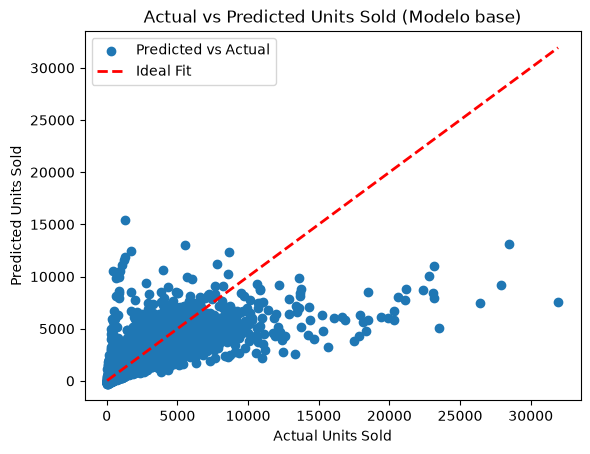

In [16]:
graficar_pred_vs_real(y_test_lineal, y_pred, "(Modelo base)")

### Modelos finales

#### Preparar datos 

- Aplicar OneHotEncoder a categóricas y StandardScaler a numéricas
- Esto fue guardado en preprocessing.py como la función build_preprocessor(X)
- Los datos fueron separados en entrenamiento y prueba en la sección "Crear variables de Predicción y objetivo"



In [17]:
from pipelines.preprocessing import build_preprocessor
preprocessor = build_preprocessor(X_train_final)

#### Modelo Lineal

Mean Squared Error (Train): 302191.83
R^2 Score (Train): 0.77


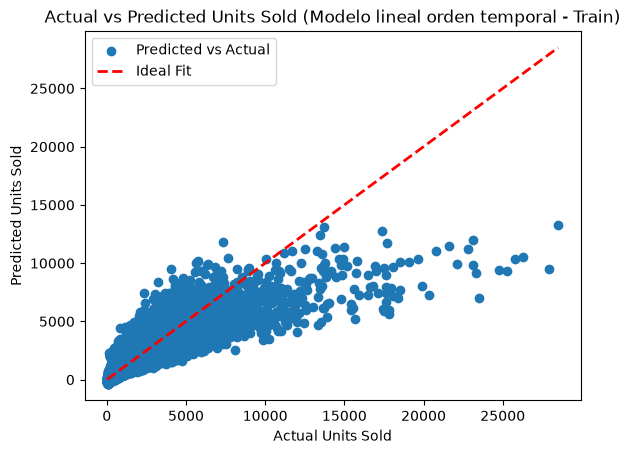

Mean Squared Error (Test): 1016827.77
R^2 Score (Test): 0.61


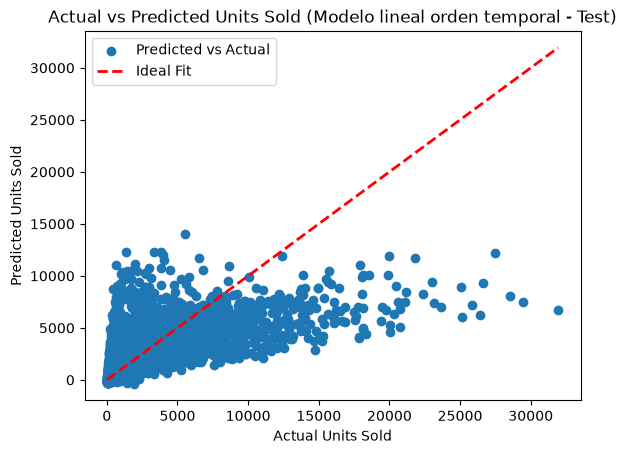

In [18]:
# Preparar el pipeline del modelo lineal con preprocesamiento de datos
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

# Entrenar el modelo lineal
model.fit(X_train_final, y_train_final)

# Evaluar el modelo lineal con los datos de entrenamiento
y_pred_train = model.predict(X_train_final)
mse_train = mean_squared_error(y_train_final, y_pred_train)
r2_train = model.score(X_train_final, y_train_final)
print(f"Mean Squared Error (Train): {mse_train:.2f}")
print(f"R^2 Score (Train): {r2_train:.2f}")
graficar_pred_vs_real(y_train_final, y_pred_train, "(Modelo lineal orden temporal - Train)")

# Guardar el modelo
models_ouput["lineal"] = {
    "fecha_de_entrenamiento": pd.to_datetime("now"),
    "model_name": "LinearRegression",
    "model": model,
    "R2_train": round(r2_train, 2),
    "MSE_train": round(mse_train, 2)
}


# Evaluar el modelo lineal con los datos de prueba
y_pred = model.predict(X_test_final)
mse = mean_squared_error(y_test_final, y_pred)
r2 = model.score(X_test_final, y_test_final)
print(f"Mean Squared Error (Test): {mse:.2f}")
print(f"R^2 Score (Test): {r2:.2f}")
graficar_pred_vs_real(y_test_final, y_pred, "(Modelo lineal orden temporal - Test)")


models_ouput["lineal"].update({
    "R2_test": round(r2, 2),
    "MSE_test": round(mse, 2)
})

#### Modelo LightGBM

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.026832 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3478
[LightGBM] [Info] Number of data points in the train set: 157832, number of used features: 125
[LightGBM] [Info] Start training from score 1135.652523
Mean Squared Error (Train): 177076.91
R^2 Score (Train): 0.87


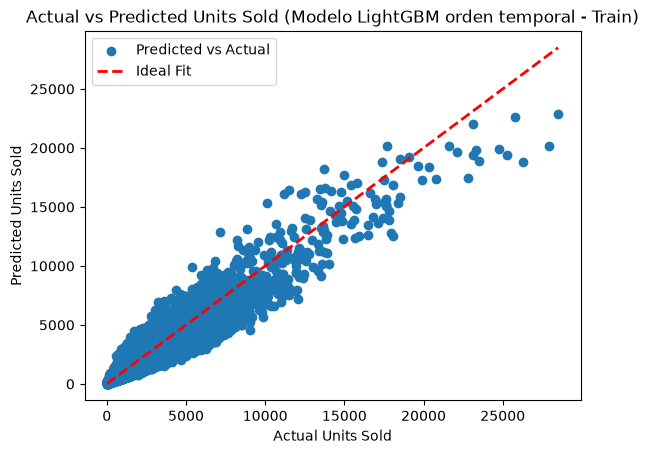

Mean Squared Error (Test): 898738.12
R^2 Score (Test): 0.65


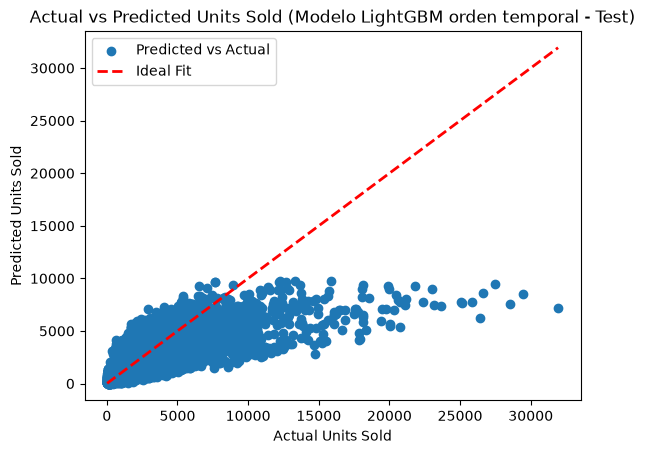

In [20]:
# Preparar el pipeline del LightGBM (orden temporal)
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LGBMRegressor()),
])
# Entrenar el modelo LightGBM
model.fit(X_train_final, y_train_final)


# Evaluar el modelo con los datos de entrenamiento
y_pred_train = model.predict(X_train_final)
mse_train = mean_squared_error(y_train_final, y_pred_train)
r2_train = model.score(X_train_final, y_train_final)
print(f"Mean Squared Error (Train): {mse_train:.2f}")
print(f"R^2 Score (Train): {r2_train:.2f}")
graficar_pred_vs_real(y_train_final, y_pred_train, "(Modelo LightGBM orden temporal - Train)")

# Guardar el modelo
models_ouput["lightgbm"] = {
    "fecha_de_entrenamiento": pd.to_datetime("now"),
    "model_name": "LGBMRegressor",
    "model": model,
    "R2_train": round(r2_train, 2),
    "MSE_train": round(mse_train, 2)
}


# Evaluar el modelo con los datos de prueba
y_pred = model.predict(X_test_final)
mse = mean_squared_error(y_test_final, y_pred)
r2 = model.score(X_test_final, y_test_final)
print(f"Mean Squared Error (Test): {mse:.2f}")
print(f"R^2 Score (Test): {r2:.2f}")
graficar_pred_vs_real(y_test_final, y_pred, "(Modelo LightGBM orden temporal - Test)")

models_ouput["lightgbm"].update({
    "R2_test": round(r2, 2),
    "MSE_test": round(mse, 2)
})

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.030589 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3483
[LightGBM] [Info] Number of data points in the train set: 158272, number of used features: 126
[LightGBM] [Info] Start training from score 1175.735253
Mean Squared Error (Train): 197262.73
R^2 Score (Train): 0.88


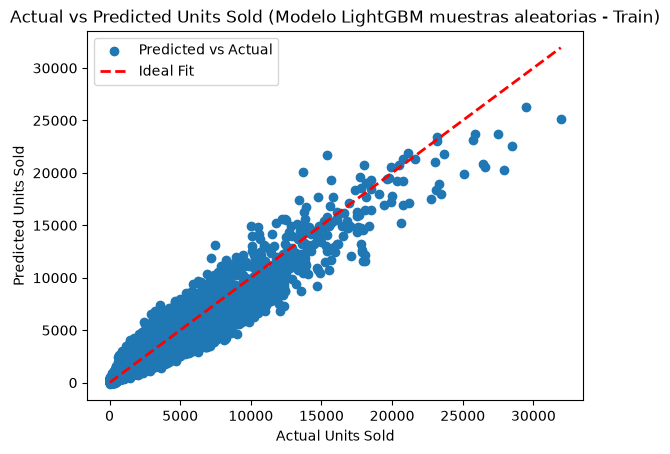

Mean Squared Error (Test): 245899.82
R^2 Score (Test): 0.84


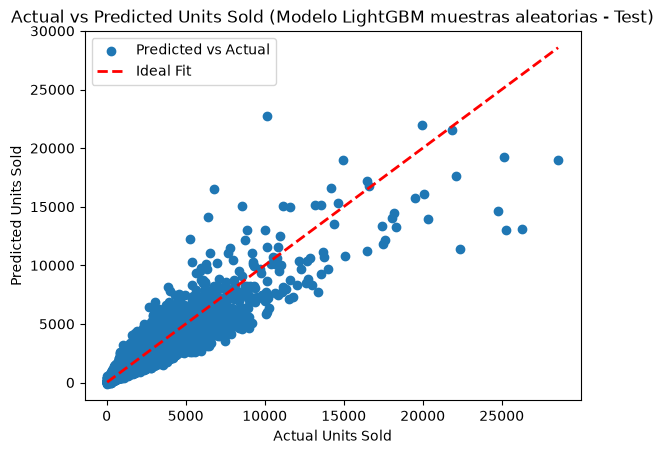

In [21]:
## Comparativa contra muestras aleatorias (solo LightGBM)
# Preparar el pipeline del LightGBM
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LGBMRegressor()),
])
# Entrenar el modelo LightGBM
model.fit(X_train, y_train)

# Evaluar el modelo con datos de entrenamiento
y_pred_train = model.predict(X_train)
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = model.score(X_train, y_train)
print(f"Mean Squared Error (Train): {mse_train:.2f}")
print(f"R^2 Score (Train): {r2_train:.2f}")
# Graficar predicciones vs valores reales en el conjunto de entrenamiento
graficar_pred_vs_real(y_train, y_pred_train, "(Modelo LightGBM muestras aleatorias - Train)")

# Guardar el modelo
models_ouput["lightgbm_random_samples"] = {
    "fecha_de_entrenamiento": pd.to_datetime("now"),
    "model_name": "LGBMRegressor",
    "model": model,
    "R2_train": round(r2_train, 2),
    "MSE_train": round(mse_train, 2)
}

# Evaluar el modelo con datos de prueba
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = model.score(X_test, y_test)
print(f"Mean Squared Error (Test): {mse:.2f}")
print(f"R^2 Score (Test): {r2:.2f}")
# Graficar predicciones vs valores reales en el conjunto de prueba
graficar_pred_vs_real(y_test, y_pred, "(Modelo LightGBM muestras aleatorias - Test)")

models_ouput["lightgbm_random_samples"].update({
    "R2_test": round(r2, 2),
    "MSE_test": round(mse, 2)
})

In [22]:
# Guardar los modelos entrenados y sus métricas
import joblib
current_date_str = pd.to_datetime("now", format="%Y-%m-%d %H:%M").strftime("%Y%m%d%H")
ruta_de_guardado = os.path.join("..","modelos")
for model_key, model_info in models_ouput.items():
    os.makedirs(ruta_de_guardado, exist_ok=True)
    joblib.dump(model_info["model"], os.path.join(ruta_de_guardado, f"{model_key}_model.joblib"))

## Conclusiones

- El modelo base presenta un (R^2) de 0.66 y un MSE de aproximadamente 580,000, frente a 0.61 y 1,020,000 del modelo lineal, y 0.65 y 899,000 de LightGBM. En esta evaluación, los modelos más complejos no muestran una mejora clara respecto al modelo base.

- El rendimiento disminuye al evaluar periodos posteriores. El (R^2) del modelo lineal baja de 0.77 en entrenamiento a 0.61 en test, mientras que LightGBM pasa de 0.87 a 0.65. Este deterioro podría estar relacionado con cambios en la distribución de la demanda entre ambos periodos. El análisis exploratorio identificó una mayor concentración de ventas en noviembre y diciembre, por lo que conviene comprobar si estos meses están representados en el conjunto de prueba y cómo afectan al error.

- LightGBM mejora moderadamente al modelo lineal en test temporal. Su MSE disminuye aproximadamente un 12 % y su (R^2) aumenta cuatro puntos porcentuales. Aunque LightGBM presenta un mejor ajuste en entrenamiento, la diferencia de rendimiento en test es más limitada, por lo que no puede concluirse que su mayor complejidad aporte una ventaja sustancial.

- La partición aleatoria produce métricas más favorables, pero no representa adecuadamente la predicción futura. LightGBM obtiene un (R^2) de 0.84 y un MSE de aproximadamente 246,000 con esta estrategia, frente a 0.65 y 899,000 con la partición temporal. La diferencia evidencia la importancia de respetar el orden cronológico al evaluar modelos de pronóstico. Las métricas aleatorias no deben utilizarse como estimación principal del rendimiento futuro.

- La diferencia entre entrenamiento y test requiere un análisis adicional. La brecha de rendimiento observada en LightGBM puede reflejar tanto sobreajuste como cambios temporales en la demanda. Con los resultados disponibles no es posible determinar qué proporción corresponde a cada factor.

Limitaciones y trabajo futuro:

- Implementar validación temporal mediante TimeSeriesSplit u otra estrategia de origen móvil (rolling-origin validation) para comprobar la estabilidad del rendimiento entre distintos periodos.

- Definir una evaluación que reproduzca el horizonte de predicción de siete días y garantice que las variables utilizadas estén disponibles en el momento de generar el pronóstico.

- Analizar el error por mes, tienda y categoría, prestando especial atención a los periodos de demanda elevada, como noviembre y diciembre.

- Evaluar métricas adicionales, como RMSE y MAE, para complementar el MSE y facilitar la interpretación del error en unidades vendidas.